# TP 3 — K plus proches voisins (KNN)
**Machine Learning · Apprentissage supervisé · Classification et régression**

Ce TP reprend les exemples de la présentation (diapos 23 à 31) :

| Exemple | Diapos | Problème |
|---|---|---|
| Exemple 1 | 25 | Classification : une feuille de 5 cm est-elle d’olivier ou de figuier ? (K = 3) |
| Exemple 2 | 26 | Régression : loyer d’un appartement de 35 m² (K = 2) |
| Exemple 3 | 27 – 31 | Démarche complète avec scikit-learn : séparer, normaliser, choisir K, évaluer |

**Objectifs** : programmer le KNN **en Python pur** (distance, rang, vote ou moyenne),  puis comparer avec **scikit-learn** (`KNeighborsClassifier`, `KNeighborsRegressor`).

## Rappel de cours

Le KNN **n’apprend aucun paramètre** : il mémorise les exemples, et tout le calcul se fait au moment de prédire.
1. **Distance** entre le nouvel exemple et chaque exemple connu. Avec une variable : $|x - x_i|$. Avec plusieurs : distance euclidienne $d = \sqrt{\sum_j (x_j - x_{ij})^2}$.
2. **Rang** : on trie les distances (rang 1 = le plus proche).
3. On garde les **K plus proches**.
4. **Classification** : vote majoritaire. **Régression** : moyenne des valeurs des voisins.

Hyperparamètre à choisir : **K** (K impair en classification binaire pour éviter les égalités).

---
# Partie A — Implémentation from scratch (Python pur)

## Exemple 1 : olivier ou figuier ?

| N° | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|
| Longueur (cm) | 1 | 3 | 4 | 8 | 10 | 11 |
| Espèce | olivier | olivier | olivier | figuier | figuier | figuier |

Nouvelle feuille : **5 cm**, K = 3.

In [2]:
longueurs = [1, 3, 4, 8, 10, 11]
especes = ["olivier", "olivier", "olivier", "figuier", "figuier", "figuier"]
nouvelle = 5
K = 3

### Question 1 — Étape 1 : distance à chaque feuille connue
**Réponse.** Avec une seule variable, la distance est l’écart absolu : $|5 - 4| = 1$ cm, $|5 - 1| = 4$ cm, etc. → distances 4 ; 2 ; 1 ; 3 ; 5 ; 6.

In [15]:
import math;
def distance(a, b):
    # Distance euclidienne ; a et b peuvent être des nombres ou des listes de nombres
    if not isinstance(a, (list, tuple)):
        a, b = [a], [b]
    return math.sqrt(sum((aj - bj) ** 2 for aj, bj in zip(a, b)))

distances = [distance(nouvelle, x) for x in longueurs]
print("Distances :", distances)



Distance : 1.0
Distances : [4.0, 2.0, 1.0, 3.0, 5.0, 6.0]


### Question 2 — Étape 2 : classer les feuilles (rangs)
**Réponse.** On trie les distances par ordre croissant. Rang 1 = feuille de 4 cm (distance 1), rang 2 = 3 cm (distance 2), rang 3 = 8 cm (distance 3)… → rangs 4 ; 2 ; 1 ; 3 ; 5 ; 6.

In [17]:
def rangs(distances):
    ordre = sorted(range(len(distances)), key=lambda i: distances[i])   # indices du plus proche au plus loin
    r = [0] * len(distances)
    for position, i in enumerate(ordre, start=1):
        r[i] = position
    return r, ordre

r, ordre = rangs(distances)
print("Rangs :", r)
assert r == [4, 2, 1, 3, 5, 6]


Rangs : [4, 2, 1, 3, 5, 6]


### Question 3 — Étapes 3 et 4 : garder les K = 3 plus proches et voter
**Réponse.** Les 3 plus proches sont 4 cm (olivier), 3 cm (olivier) et 8 cm (figuier) → 2 voix contre 1 → **olivier**.

In [18]:
def knn_classer(X, y, x_nouveau, K):
    d = [distance(x_nouveau, xi) for xi in X]
    _, ordre = rangs(d)
    voisins = ordre[:K]
    votes = {}
    for i in voisins:
        votes[y[i]] = votes.get(y[i], 0) + 1
    gagnant = max(votes, key=votes.get)
    return gagnant, voisins, votes

classe, voisins, votes = knn_classer(longueurs, especes, nouvelle, K)
print("Voisins retenus :", [(longueurs[i], especes[i]) for i in voisins])
print("Votes :", votes, "→", classe)
assert [longueurs[i] for i in voisins] == [4, 3, 8] and classe == "olivier"
print("✅ C'est une feuille d'olivier ")

Voisins retenus : [(4, 'olivier'), (3, 'olivier'), (8, 'figuier')]
Votes : {'olivier': 2, 'figuier': 1} → olivier
✅ C'est une feuille d'olivier 


## Exemple 2 : loyer d’un appartement

| N° | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| Surface (m²) | 20 | 30 | 60 | 80 |
| Loyer (TND) | 400 | 550 | 900 | 1100 |

Nouvel appartement : **35 m²**, K = 2.

### Question 4 — Prédire le loyer
**Réponse.** Distances : 15 ; 5 ; 25 ; 45 → rangs 2 ; 1 ; 3 ; 4. Les 2 plus proches sont 30 m² (550 TND) et 20 m² (400 TND). En régression, on ne vote pas : on fait la **moyenne** → $(550 + 400)/2 = 475$ TND.

In [19]:
surfaces = [20, 30, 60, 80]
loyers = [400, 550, 900, 1100]

def knn_regression(X, y, x_nouveau, K):
    d = [distance(x_nouveau, xi) for xi in X]
    _, ordre = rangs(d)
    voisins = ordre[:K]
    return sum(y[i] for i in voisins) / K, voisins, d

loyer, voisins, d = knn_regression(surfaces, loyers, 35, K=2)
print("Distances :", d, "| rangs :", rangs(d)[0])
print("Voisins :", [(surfaces[i], loyers[i]) for i in voisins])
assert rangs(d)[0] == [2, 1, 3, 4]


Distances : [15.0, 5.0, 25.0, 45.0] | rangs : [2, 1, 3, 4]
Voisins : [(30, 550), (20, 400)]


---
# Partie B — Les mêmes exemples avec scikit-learn

### Question 5 — `KNeighborsClassifier` et `KNeighborsRegressor`
**Réponse.** Dans scikit-learn, `fit()` ne fait que **mémoriser** les données, comme dans notre version. `kneighbors()` renvoie les distances et les indices des voisins : on peut donc comparer les voisins eux-mêmes, pas seulement le résultat.

In [20]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

Xf = np.array(longueurs).reshape(-1, 1)
clf = KNeighborsClassifier(n_neighbors=3).fit(Xf, especes)
dist_sk, idx_sk = clf.kneighbors([[nouvelle]])
print("Classification : voisins =", Xf[idx_sk[0]].ravel(), "distances =", dist_sk[0], "→", clf.predict([[nouvelle]])[0])
print("                 probabilités", dict(zip(clf.classes_, clf.predict_proba([[nouvelle]])[0].round(3))))

Xs = np.array(surfaces).reshape(-1, 1)
reg = KNeighborsRegressor(n_neighbors=2).fit(Xs, loyers)
dist_r, idx_r = reg.kneighbors([[35]])
print("Régression     : voisins =", Xs[idx_r[0]].ravel(), "distances =", dist_r[0], "→", reg.predict([[35]])[0], "TND")

Classification : voisins = [4 3 8] distances = [1. 2. 3.] → olivier
                 probabilités {np.str_('figuier'): np.float64(0.333), np.str_('olivier'): np.float64(0.667)}
Régression     : voisins = [30 20] distances = [ 5. 15.] → 475.0 TND


### Question 6 — Exemple 3 : la démarche complète


In [21]:
import pandas as pd
rng = np.random.default_rng(42)
n = 1500
surface = rng.uniform(30, 220, n)
pieces = np.clip(np.round(surface / 35 + rng.normal(0, 0.6, n)), 1, 7)
dist_centre = rng.uniform(0.5, 15, n)
etage = rng.integers(0, 11, n)
age = rng.uniform(0, 50, n)
ascenseur = rng.integers(0, 2, n)
prix = (1.0 * surface + 6 * pieces - 6 * dist_centre + 4 * etage - 1.2 * age
        + 40 * ascenseur + 150 + rng.normal(0, 25, n))         # prix en kDT, bruit σ = 25
prix = np.maximum(prix, 20)                                    # pas de prix aberrant
X = pd.DataFrame({"surface": surface, "pieces": pieces, "distance_centre": dist_centre,
                  "etage": etage, "age": age, "ascenseur": ascenseur})
y = prix
display(X.describe().round(1))

,surface,pieces,distance_centre,etage,age,ascenseur
count,1500.0,1500.0,1500.0,1500.0,1500.0,1500.0
mean,124.9,3.6,7.7,5.0,24.7,0.5
std,55.4,1.7,4.2,3.1,14.4,0.5
min,30.1,1.0,0.5,0.0,0.0,0.0
25%,75.8,2.0,4.1,2.0,12.3,0.0
50%,123.9,4.0,7.7,5.0,24.7,1.0
75%,174.2,5.0,11.3,8.0,37.2,1.0
max,219.9,7.0,15.0,10.0,50.0,1.0


In [9]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# 1) Séparer : 80 % entraînement (1 200), 20 % test (300)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2) Effet de la normalisation (K = 5)
def rmse(a, b): return mean_squared_error(a, b) ** 0.5
sans = KNeighborsRegressor(n_neighbors=5).fit(X_train, y_train)
avec = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=5))]).fit(X_train, y_train)
r_sans, r_avec = rmse(y_test, sans.predict(X_test)), rmse(y_test, avec.predict(X_test))
print(f"RMSE test K=5 sans normalisation : {r_sans:.1f} kDT  (R² = {r2_score(y_test, sans.predict(X_test)):.3f})")
print(f"RMSE test K=5 avec normalisation : {r_avec:.1f} kDT  (R² = {r2_score(y_test, avec.predict(X_test)):.3f})")
assert r_avec < r_sans
print("✅ La normalisation améliore la RMSE (diapo 27 : 40,5 → 29,7 kDT)")

RMSE test K=5 sans normalisation : 36.7 kDT  (R² = 0.813)
RMSE test K=5 avec normalisation : 30.9 kDT  (R² = 0.867)
✅ La normalisation améliore la RMSE (diapo 27 : 40,5 → 29,7 kDT)


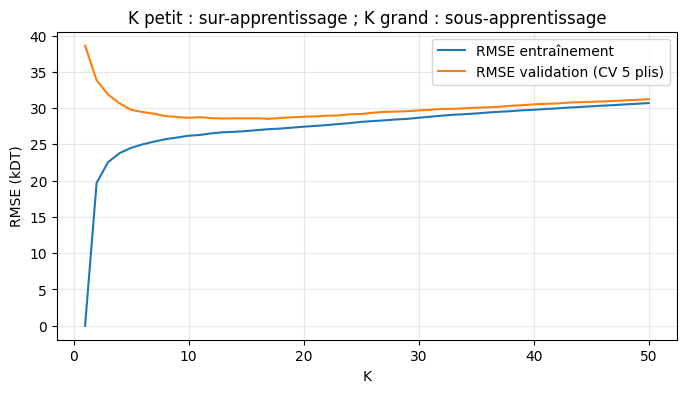

K = 1 : RMSE entraînement = 0.0 ; validation = 38.6
Meilleur K en validation : 17 (RMSE = 28.5)
✅ K = 1 : erreur d'entraînement nulle mais validation moins bonne (diapo 28)


In [10]:
# 3) Choisir K : erreur d'entraînement et erreur de validation (CV 5 plis), K = 1 à 50
Ks = range(1, 51)
rmse_train, rmse_val = [], []
for k in Ks:
    pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=k))])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error", return_train_score=True)
    rmse_train.append(-cv["train_score"].mean()); rmse_val.append(-cv["test_score"].mean())

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(Ks, rmse_train, label="RMSE entraînement"); plt.plot(Ks, rmse_val, label="RMSE validation (CV 5 plis)")
plt.xlabel("K"); plt.ylabel("RMSE (kDT)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("K petit : sur-apprentissage ; K grand : sous-apprentissage"); plt.show()
k_best = Ks[int(np.argmin(rmse_val))]
print(f"K = 1 : RMSE entraînement = {abs(rmse_train[0]):.1f} ; validation = {rmse_val[0]:.1f}")
print(f"Meilleur K en validation : {k_best} (RMSE = {min(rmse_val):.1f})")
assert rmse_train[0] < 1e-6 and rmse_val[0] > min(rmse_val)
print("✅ K = 1 : erreur d'entraînement nulle mais validation moins bonne ")

In [11]:
# 4) Recherche complète avec GridSearchCV (code de la diapo 27), puis évaluation sur le test
pipeline = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])
recherche = GridSearchCV(pipeline, {"knn__n_neighbors": range(1, 41), "knn__weights": ["uniform", "distance"]},
                         cv=5, scoring="neg_root_mean_squared_error")
recherche.fit(X_train, y_train)
modele = recherche.best_estimator_
print("Meilleurs réglages :", recherche.best_params_, f"| RMSE validation = {-recherche.best_score_:.1f}")

pred = modele.predict(X_test)
naif = np.full_like(y_test, y_train.mean())
res = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, naif), mean_absolute_error(y_test, pred)],
    "RMSE": [rmse(y_test, naif), rmse(y_test, pred)],
    "R²": [r2_score(y_test, naif), r2_score(y_test, pred)],
    "MAPE": [mean_absolute_percentage_error(y_test, naif), mean_absolute_percentage_error(y_test, pred)],
}, index=["Référence naïve (moyenne)", "KNN optimisé"])
res["MAPE"] = (100 * res["MAPE"]).round(1).astype(str) + " %"
display(res.round(3))
nouvel = pd.DataFrame([{"surface": 95, "pieces": 3, "distance_centre": 4, "etage": 2, "age": 10, "ascenseur": 1}])
print(f"Prix estimé d'un 95 m² à 4 km (3 pièces, 2e étage, 10 ans, ascenseur) : {modele.predict(nouvel)[0]:.1f} kDT")
assert r2_score(y_test, pred) > 0.85 and r2_score(y_test, naif) < 0.05
print("✅ Le modèle fait bien mieux que la référence naïve ")

Meilleurs réglages : {'knn__n_neighbors': 17, 'knn__weights': 'distance'} | RMSE validation = 28.2


,MAE,RMSE,R²,MAPE
Référence naïve (moyenne),72.641,85.355,-0.015,36.4 %
KNN optimisé,23.155,29.261,0.881,11.2 %


Prix estimé d'un 95 m² à 4 km (3 pièces, 2e étage, 10 ans, ascenseur) : 272.9 kDT
✅ Le modèle fait bien mieux que la référence naïve (diapo 29)


---
# Partie C — Comparaison et validation
### Question 7 — Python pur et scikit-learn donnent-ils les mêmes voisins et les mêmes résultats ?

In [12]:
lignes = [
    ("Ex.1 voisins (cm)", "4, 3, 8", ", ".join(str(longueurs[i]) for i in knn_classer(longueurs, especes, 5, 3)[1]),
        ", ".join(str(v) for v in Xf[idx_sk[0]].ravel())),
    ("Ex.1 classe", "olivier", classe, clf.predict([[5]])[0]),
    ("Ex.2 voisins (m²)", "30, 20", ", ".join(str(surfaces[i]) for i in voisins), ", ".join(str(v) for v in Xs[idx_r[0]].ravel())),
    ("Ex.2 loyer (TND)", 475, loyer, reg.predict([[35]])[0]),
]
display(pd.DataFrame(lignes, columns=["Grandeur", "Diapo", "Python pur", "scikit-learn"]))
assert classe == clf.predict([[5]])[0] and loyer == reg.predict([[35]])[0]
assert sorted(knn_classer(longueurs, especes, 5, 3)[1]) == sorted(idx_sk[0].tolist())

# Contrôle supplémentaire : sur des données à 6 variables, notre KNN pur donne les mêmes prédictions que scikit-learn
Xtr_s = StandardScaler().fit(X_train).transform(X_train)[:200].tolist()
Xte_s = StandardScaler().fit(X_train).transform(X_test)[:20].tolist()
ytr_l = list(np.asarray(y_train)[:200])
nos_pred = [knn_regression(Xtr_s, ytr_l, x, 5)[0] for x in Xte_s]
sk_pred = KNeighborsRegressor(n_neighbors=5).fit(Xtr_s, ytr_l).predict(Xte_s)
assert np.allclose(nos_pred, sk_pred)
print("✅ Python pur = scikit-learn (mêmes voisins, mêmes prédictions), aussi en 6 dimensions")

,Grandeur,Diapo,Python pur,scikit-learn
0,Ex.1 voisins (cm),"4, 3, 8","4, 3, 8","4, 3, 8"
1,Ex.1 classe,olivier,olivier,olivier
2,Ex.2 voisins (m²),"30, 20","30, 20","30, 20"
3,Ex.2 loyer (TND),475,475.0,475.0


✅ Python pur = scikit-learn (mêmes voisins, mêmes prédictions), aussi en 6 dimensions


## Conclusion

| Ce qu’on a vérifié | Résultat |
|---|---|
| Exemple 1 : distances, rangs, voisins (4, 3, 8 cm), vote → olivier | ✅ identique à scikit-learn |
| Exemple 2 : voisins 30 et 20 m², loyer 475 TND | ✅ identique à scikit-learn |
| Exemple 3 : normalisation, choix de K, évaluation | ✅ mêmes conclusions que les diapos (jeu de données régénéré, donc chiffres proches mais différents) |

**À retenir**
- Le KNN n’a **aucun paramètre appris** : `fit()` mémorise, `predict()` calcule les distances.
- **Normaliser** est indispensable dès qu’il y a plusieurs variables d’échelles différentes.
- K se choisit par **validation croisée** : K = 1 colle au bruit, un K trop grand lisse trop.